In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from wordcloud import WordCloud

In [2]:
#Loading data 

data = pd.read_csv("Reviews.csv")
data

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...
...,...,...,...,...,...,...,...,...,...,...
568449,568450,B001EO7N10,A28KG5XORO54AY,Lettie D. Carter,0,0,5,1299628800,Will not do without,Great for sesame chicken..this is a good if no...
568450,568451,B003S1WTCU,A3I8AFVPEE8KI5,R. Sawyer,0,0,2,1331251200,disappointed,I'm disappointed with the flavor. The chocolat...
568451,568452,B004I613EE,A121AA1GQV751Z,"pksd ""pk_007""",2,2,5,1329782400,Perfect for our maltipoo,"These stars are small, so you can give 10-15 o..."
568452,568453,B004I613EE,A3IBEVCTXKNOH,"Kathy A. Welch ""katwel""",1,1,5,1331596800,Favorite Training and reward treat,These are the BEST treats for training and rew...


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


In [4]:
#Dealing null values 

data.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [5]:
#Deleting null values of summary only, cause ProfileName is not gonna be used 
data.dropna(subset=["Summary"],inplace=True)

In [6]:
data.dtypes

Id                         int64
ProductId                 object
UserId                    object
ProfileName               object
HelpfulnessNumerator       int64
HelpfulnessDenominator     int64
Score                      int64
Time                       int64
Summary                   object
Text                      object
dtype: object

In [7]:
#Removing the columns which are not useful 

data_usefull=data[["Score","Summary","Text"]]

In [8]:
data_usefull

,Score,Summary,Text
0,5,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,1,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,4,"""Delight"" says it all",This is a confection that has been around a fe...
3,2,Cough Medicine,If you are looking for the secret ingredient i...
4,5,Great taffy,Great taffy at a great price. There was a wid...
...,...,...,...
568449,5,Will not do without,Great for sesame chicken..this is a good if no...
568450,2,disappointed,I'm disappointed with the flavor. The chocolat...
568451,5,Perfect for our maltipoo,"These stars are small, so you can give 10-15 o..."
568452,5,Favorite Training and reward treat,These are the BEST treats for training and rew...


In [9]:
#Count of the reviews 

data_usefull["Score"].value_counts().sort_index()

Score
1     52268
2     29744
3     42638
4     80655
5    363122
Name: count, dtype: int64

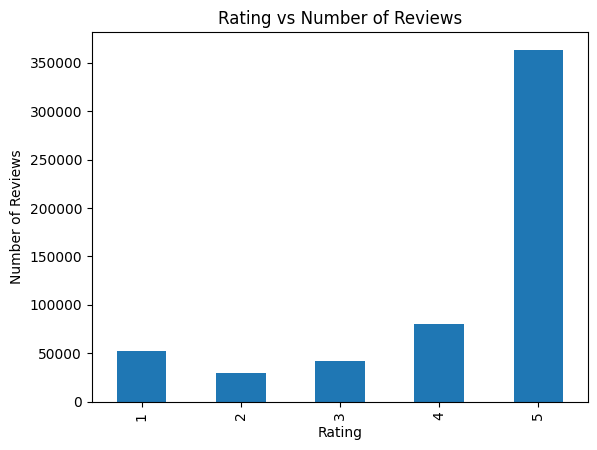

In [10]:
#BarPlot Review vs count 

rating_counts = data_usefull["Score"].value_counts().sort_index()

plt.figure()
rating_counts.plot(kind="bar")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.title("Rating vs Number of Reviews")
plt.show()


In [11]:
#Percentage of each rating 

rating_counts = data_usefull["Score"].value_counts().sort_index()
percentage = (rating_counts/rating_counts.sum())*100
percentage 

Score
1     9.195200
2     5.232686
3     7.501051
4    14.189157
5    63.881906
Name: count, dtype: float64

In [12]:
#Fuction for applying lable to the ratings 
# 1-2 = Negitive 
# 3 = Neutral
# 4-5 = Poitive


def create_label(rating):
    if rating <= 2:
        return 0
    elif rating == 3:
        return 1   
    else:
        return 2  

In [13]:
#Creating new column lables(for labling according to rating)

data_usefull["labels"] = data_usefull["Score"].apply(create_label)

/tmp/ipykernel_9651/2553446089.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_usefull["labels"] = data_usefull["Score"].apply(create_label)


In [15]:
#Checking values according to lables

data_usefull["labels"].value_counts().sort_index()

labels
0     82012
1     42638
2    443777
Name: count, dtype: int64

In [16]:
#Percentage of each Lable

rating_counts = data_usefull["labels"].value_counts().sort_index()
percentage = (rating_counts/rating_counts.sum())*100
percentage 

labels
0    14.427886
1     7.501051
2    78.071063
Name: count, dtype: float64

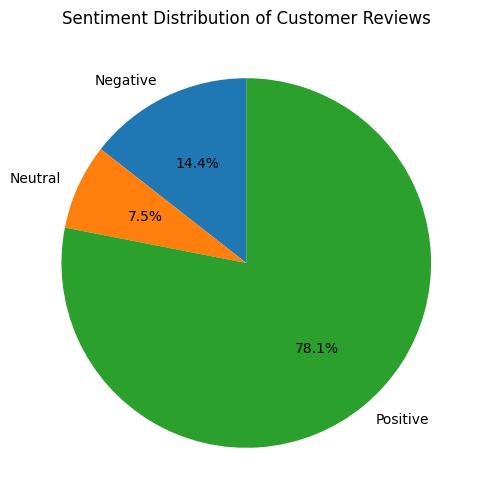

In [17]:
#Pie plot for lables percentage 

labels = ["Negative", "Neutral", "Positive"]

plt.figure(figsize=(6, 6))
plt.pie(
    percentage,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Sentiment Distribution of Customer Reviews")
plt.show()


In [18]:
#Merging Summary and Text column to get full review in New column "Review"

data_usefull["Review"] = (data_usefull["Summary"].fillna("") + " " + data_usefull["Text"].fillna(""))

/tmp/ipykernel_9651/2356813134.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_usefull["Review"] = (data_usefull["Summary"].fillna("") + " " + data_usefull["Text"].fillna(""))


In [19]:
data_usefull

,Score,Summary,Text,labels,Review
0,5,Good Quality Dog Food,I have bought several of the Vitality canned d...,2,Good Quality Dog Food I have bought several of...
1,1,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...,0,Not as Advertised Product arrived labeled as J...
2,4,"""Delight"" says it all",This is a confection that has been around a fe...,2,"""Delight"" says it all This is a confection tha..."
3,2,Cough Medicine,If you are looking for the secret ingredient i...,0,Cough Medicine If you are looking for the secr...
4,5,Great taffy,Great taffy at a great price. There was a wid...,2,Great taffy Great taffy at a great price. The...
...,...,...,...,...,...
568449,5,Will not do without,Great for sesame chicken..this is a good if no...,2,Will not do without Great for sesame chicken.....
568450,2,disappointed,I'm disappointed with the flavor. The chocolat...,0,disappointed I'm disappointed with the flavor....
568451,5,Perfect for our maltipoo,"These stars are small, so you can give 10-15 o...",2,Perfect for our maltipoo These stars are small...
568452,5,Favorite Training and reward treat,These are the BEST treats for training and rew...,2,Favorite Training and reward treat These are t...


In [20]:
#Join text for each Review

neg_text = " ".join(data_usefull[data_usefull["labels"] == 0]["Review"])
neu_text = " ".join(data_usefull[data_usefull["labels"] == 1]["Review"])
pos_text = " ".join(data_usefull[data_usefull["labels"] == 2]["Review"])

In [21]:
wc = WordCloud(
    width=600,
    height=400,
    background_color="white",
    max_words=150
)

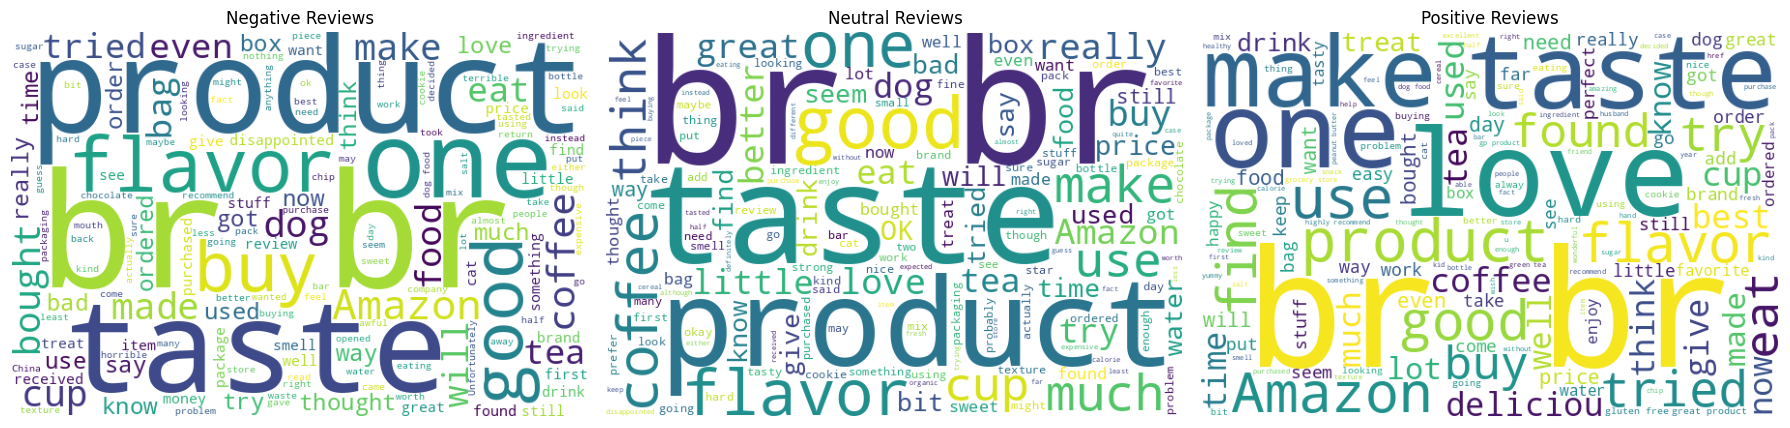

In [23]:
#Wordcloud plot 

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Negative
axes[0].imshow(wc.generate(neg_text))
axes[0].set_title("Negative Reviews")
axes[0].axis("off")

# Neutral
axes[1].imshow(wc.generate(neu_text))
axes[1].set_title("Neutral Reviews")
axes[1].axis("off")

# Positive
axes[2].imshow(wc.generate(pos_text))
axes[2].set_title("Positive Reviews")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [25]:
#from wordcloud we can see that there were html tags present in the reviews so lets deal with themmm

import re

def remove_html_regex(text):
    return re.sub(r'<.*?>', ' ', text)

data_usefull["Review"] = data_usefull["Review"].apply(remove_html_regex)

/tmp/ipykernel_9651/2180868469.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_usefull["Review"] = data_usefull["Review"].apply(remove_html_regex)


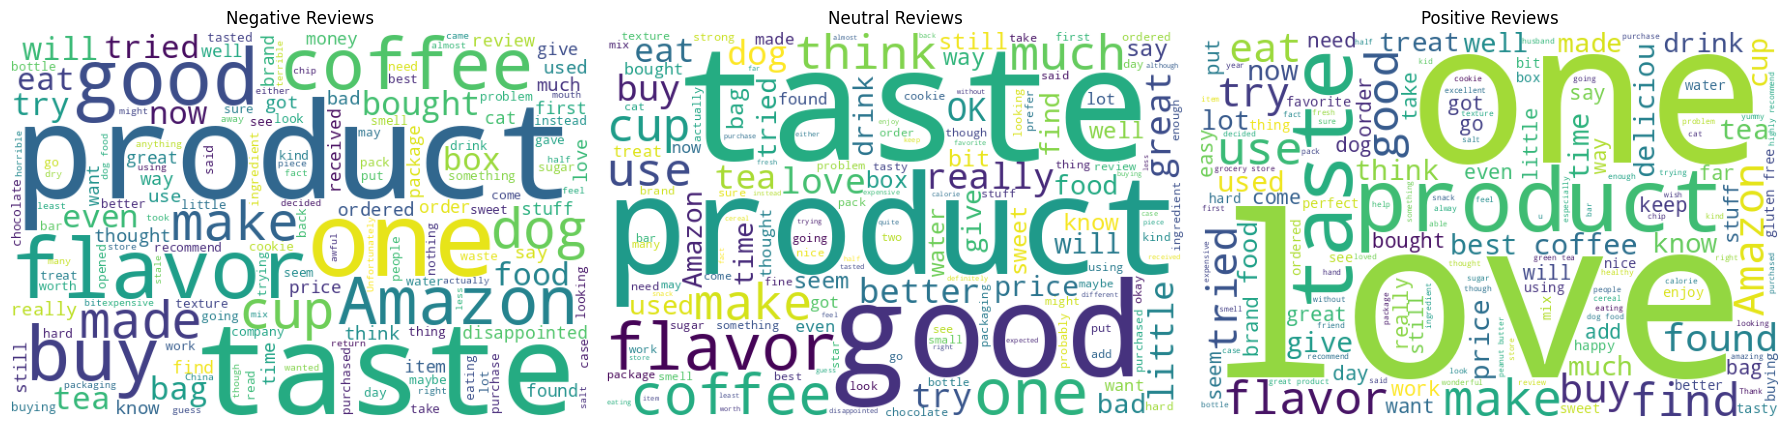

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Negative
axes[0].imshow(wc.generate(neg_text))
axes[0].set_title("Negative Reviews")
axes[0].axis("off")

# Neutral
axes[1].imshow(wc.generate(neu_text))
axes[1].set_title("Neutral Reviews")
axes[1].axis("off")

# Positive
axes[2].imshow(wc.generate(pos_text))
axes[2].set_title("Positive Reviews")
axes[2].axis("off")

plt.tight_layout()
plt.show()


In [33]:
#Creating equall samples for training, as we observe the count of positive review is huge in count that can imbalance our models decision

SAMPLES_PER_CLASS = 40000 #cause the count of neutral is around 42000

balanced_df = (
    data_usefull[["Review","labels"]]
    .groupby("labels", group_keys=False)
    .apply(lambda x: x.sample(SAMPLES_PER_CLASS, random_state=42))
    .reset_index(drop=True)
)

/tmp/ipykernel_9651/1075314406.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(SAMPLES_PER_CLASS, random_state=42))


In [34]:
balanced_df["labels"].value_counts().sort_index()

labels
0    40000
1    40000
2    40000
Name: count, dtype: int64

In [37]:
#saving the new sample dataset 

final_df = balanced_df[["Review", "labels"]].copy()
final_df.columns = ["text", "label"]
final_df.to_csv("final_customer_sentiment_dataset.csv", index=False)